# N2 — Avaliação e demonstração do recomendador de livros do BookLog

**Universidade Presbiteriana Mackenzie — Faculdade de Computação e Informática**
Inteligência Artificial — 7ºK — Sistemas de Informação — 2026/2 — Prof. Dr. Leandro Zerbinatti

| Integrante | RA | E-mail |
|---|---|---|
| Gabriel Nottoli Buck | 10425384 | 10425384@mackenzista.com.br |
| Julia Andrade | 10427828 | 10427828@mackenzista.com.br |
| João Vitor Rocha Miranda | 10427273 | 10427273@mackenzista.com.br |
| Juan Nacif | 10428509 | 10428509@mackenzista.com.br |

**Finalidade:** executar a avaliação offline da N2 (`src/avaliacao_n2.py`), apresentar as métricas e demonstrar as recomendações de um leitor acadêmico, comparando o baseline de popularidade com o híbrido do backend.

**Histórico:** 18/11/2026 — Grupo — criação do notebook de avaliação e demonstração da N2.

> A base (30 leitores, 36 livros, 345 avaliações) foi elaborada pelo grupo para a disciplina. **Não são dados reais de usuários do BookLog.** Nada aqui acessa banco, API ou serviços de produção.

Pré-requisito (uma vez, fora do vídeo): `pip install -r requirements.txt`, `npm --prefix snapshot ci` e `npm --prefix snapshot run build`.

## 1. Execução da avaliação
A célula abaixo executa o protocolo completo: separação temporal, cinco estratégias (as três do backend via cópia acadêmica em TypeScript), métricas, bootstrap e gráficos. Todos os arquivos em `results/` são regenerados.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import avaliacao_n2 as A

A.main()

Treino: 273 | Teste: 72 | Leitores avaliados: 20 | Relevantes no teste: 29 | Vocabulário TF-IDF: 129
              label  k  precision  recall  ndcg  coverage
       Popularidade  5      0.100   0.308 0.230      33.3
       Popularidade 10      0.055   0.333 0.239      55.6
             TF-IDF  5      0.160   0.542 0.356      91.7
             TF-IDF 10      0.120   0.800 0.451      97.2
Conteúdo do backend  5      0.170   0.533 0.370      88.9
Conteúdo do backend 10      0.100   0.658 0.413     100.0
 Híbrido do backend  5      0.160   0.508 0.374      94.4
 Híbrido do backend 10      0.100   0.658 0.427     100.0
   Grafo do backend  5      0.150   0.517 0.313      94.4
   Grafo do backend 10      0.105   0.708 0.383     100.0

Bootstrap pareado (NDCG):
             comparison  metric  mean_difference  ci95_low  ci95_high
   tfidf - popularidade  ndcg@5            0.126    -0.035      0.284
conteudo - popularidade  ndcg@5            0.140    -0.033      0.310
 hibrido - popularidade 

## 2. Caracterização e separação temporal
Corte global em 10/09/2026: avaliações anteriores formam o treino; a partir dessa data, o teste. Popularidade, notas agregadas e coocorrência usam somente o treino.

In [2]:
split = json.loads((ROOT / "results/split_summary.json").read_text(encoding="utf-8"))
ratings = pd.read_csv(ROOT / "data/processed/ratings_clean.csv")
books = pd.read_csv(ROOT / "data/processed/books_clean.csv")
train = pd.read_csv(ROOT / "data/processed/train.csv")
test = pd.read_csv(ROOT / "data/processed/test.csv")
pd.DataFrame({
    "Indicador": ["Leitores", "Livros", "Avaliações", "Esparsidade",
                  f"Treino ({split['train']['first_date']} a {split['train']['last_date']})",
                  f"Teste ({split['test']['first_date']} a {split['test']['last_date']})",
                  "Menor histórico de treino por leitor", "Leitores com avaliação no teste",
                  "Avaliações relevantes no teste (nota ≥ 4)", "Leitores avaliados (≥ 1 relevante)",
                  "Vocabulário TF-IDF"],
    "Valor": [ratings.user_id.nunique(), len(books), len(ratings),
              f"{1 - len(ratings) / (ratings.user_id.nunique() * len(books)):.1%}",
              split["train"]["ratings"], split["test"]["ratings"], split["train"]["min_ratings_per_user"],
              split["test"]["users_with_test"], split["test"]["relevant_ratings"],
              split["test"]["users_with_relevant"], split["tfidf_vocabulary_size"]],
})

,Indicador,Valor
0,Leitores,30
1,Livros,36
2,Avaliações,345
3,Esparsidade,68.1%
4,Treino (2026-08-20 a 2026-09-09),273
5,Teste (2026-09-10 a 2026-09-14),72
6,Menor histórico de treino por leitor,4
7,Leitores com avaliação no teste,27
8,Avaliações relevantes no teste (nota ≥ 4),29
9,Leitores avaliados (≥ 1 relevante),20


## 3. Resultados por estratégia
Médias por leitor sobre os 20 leitores com pelo menos um relevante no teste. Cobertura = livros distintos recomendados ao conjunto avaliado ÷ 36.

In [3]:
summary = pd.read_csv(ROOT / "results/metrics_summary.csv")
for k in (5, 10):
    t = summary[summary.k == k][["label", "precision", "recall", "ndcg", "coverage"]].copy()
    t.columns = ["Estratégia", f"Precision@{k}", f"Recall@{k}", f"NDCG@{k}", "Cobertura"]
    t["Cobertura"] = (t["Cobertura"] * 100).round(1).astype(str) + "%"
    display(t.round(3).set_index("Estratégia"))

,Precision@5,Recall@5,NDCG@5,Cobertura
Estratégia,,,,
Popularidade,0.10,0.308,0.230,33.3%
TF-IDF,0.16,0.542,0.356,91.7%
Conteúdo do backend,0.17,0.533,0.370,88.9%
Híbrido do backend,0.16,0.508,0.374,94.4%
Grafo do backend,0.15,0.517,0.313,94.4%


,Precision@10,Recall@10,NDCG@10,Cobertura
Estratégia,,,,
Popularidade,0.055,0.333,0.239,55.6%
TF-IDF,0.120,0.800,0.451,97.2%
Conteúdo do backend,0.100,0.658,0.413,100.0%
Híbrido do backend,0.100,0.658,0.427,100.0%
Grafo do backend,0.105,0.708,0.383,100.0%


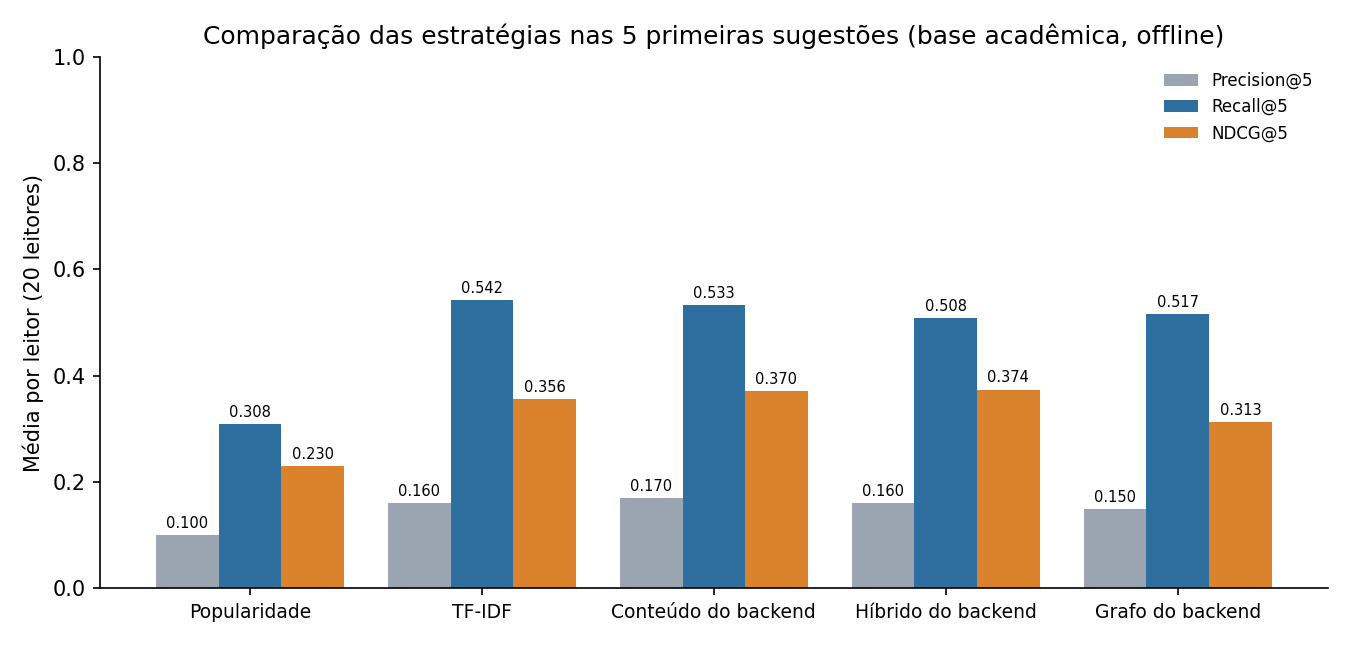

In [4]:
display(Image(filename=str(ROOT / "results/graficos/comparacao_top5.png")))

**Leitura cuidadosa:** o híbrido supera a popularidade nesta base, mas não vence todas as alternativas — conteúdo isolado tem a maior Precision@5, TF-IDF tem o maior Recall@5 e lidera as métricas em dez posições. Recall@5 mede recuperação de relevantes observados no teste offline; não é satisfação de usuários nem taxa de conversão.

## 4. Incerteza: bootstrap pareado por leitor (10.000 reamostragens, semente 42)

In [5]:
boot = pd.read_csv(ROOT / "results/paired_bootstrap.csv")
b = boot[boot.metric.str.startswith("ndcg")][["comparison", "metric", "mean_difference", "ci95_low", "ci95_high", "ci_includes_zero"]]
b.round(3)

,comparison,metric,mean_difference,ci95_low,ci95_high,ci_includes_zero
0,tfidf - popularidade,ndcg@5,0.126,-0.035,0.284,True
2,conteudo - popularidade,ndcg@5,0.140,-0.033,0.310,True
4,hibrido - popularidade,ndcg@5,0.144,-0.036,0.316,True
6,grafo - popularidade,ndcg@5,0.083,-0.110,0.273,True
8,tfidf - popularidade,ndcg@10,0.212,0.056,0.359,False
10,conteudo - popularidade,ndcg@10,0.174,-0.000,0.340,True
12,hibrido - popularidade,ndcg@10,0.188,0.010,0.353,False
14,grafo - popularidade,ndcg@10,0.144,-0.038,0.327,True


## 5. Demonstração: recomendações de um leitor acadêmico
Altere `LEITOR` para qualquer identificador de U001 a U030. A tabela mostra parte do histórico de treino, os relevantes do teste (desconhecidos pelos algoritmos) e as cinco primeiras sugestões de cada estratégia. ✔ marca acerto.

In [6]:
LEITOR = "U003"

rankings = json.loads((ROOT / "results/rankings.json").read_text(encoding="utf-8"))["rankings"]
backend = json.loads((ROOT / "results/backend-output.json").read_text(encoding="utf-8"))["results"]
titles = dict(zip(books.book_id, books.title))

def demonstrar(leitor, k=5):
    hist = train[train.user_id == leitor].merge(books, on="book_id")[["title", "genres", "author", "rating", "interaction_date"]]
    print(f"Histórico de treino de {leitor} ({len(hist)} avaliações):")
    display(hist.sort_values("rating", ascending=False).rename(columns={"title": "Livro", "genres": "Gênero", "author": "Autor", "rating": "Nota", "interaction_date": "Data"}).reset_index(drop=True))
    rel = test[(test.user_id == leitor) & (test.rating >= A.RELEVANCE_THRESHOLD)]
    rel_ids = set(rel.book_id)
    print("Relevantes no teste:", ", ".join(titles[b] for b in rel.book_id) or "nenhum (leitor fora das métricas)")
    table = pd.DataFrame({A.LABELS[s]: [("✔ " if i["book_id"] in rel_ids else "") + i["title"] for i in rankings[s][leitor][:k]] for s in A.STRATEGIES},
                         index=pd.RangeIndex(1, k + 1, name="Posição"))
    display(table)
    return rel_ids

rel_ids = demonstrar(LEITOR)

Histórico de treino de U003 (9 avaliações):


,Livro,Gênero,Autor,Nota,Data
0,Harry Potter e a Pedra Filosofal,Fantasia,J. K. Rowling,5.0,2026-08-23
1,As Crônicas de Nárnia,Fantasia,C. S. Lewis,5.0,2026-09-06
2,O Nome do Vento,Fantasia,Patrick Rothfuss,4.5,2026-08-20
3,O Código Da Vinci,Mistério,Dan Brown,4.0,2026-08-20
4,O Silêncio dos Inocentes,Mistério,Thomas Harris,3.5,2026-08-24
5,A Paciente Silenciosa,Mistério,Alex Michaelides,3.5,2026-09-09
6,O Guia do Mochileiro das Galáxias,Ficção Científica,Douglas Adams,2.5,2026-09-03
7,Fundação,Ficção Científica,Isaac Asimov,2.5,2026-09-09
8,Jogos Vorazes,Distopia,Suzanne Collins,2.0,2026-08-27


Relevantes no teste: A Sociedade do Anel, E Não Sobrou Nenhum


,Popularidade,TF-IDF,Conteúdo do backend,Híbrido do backend,Grafo do backend
Posição,,,,,
1,Duna,✔ A Sociedade do Anel,✔ A Sociedade do Anel,✔ A Sociedade do Anel,✔ A Sociedade do Anel
2,Neuromancer,O Hobbit,O Feiticeiro de Terramar,O Hobbit,O Hobbit
3,Orgulho e Preconceito,O Feiticeiro de Terramar,O Hobbit,O Feiticeiro de Terramar,O Feiticeiro de Terramar
4,Dom Casmurro,Assassinato no Expresso do Oriente,✔ E Não Sobrou Nenhum,✔ E Não Sobrou Nenhum,A Mão Esquerda da Escuridão
5,O Retrato de Dorian Gray,✔ E Não Sobrou Nenhum,Assassinato no Expresso do Oriente,Assassinato no Expresso do Oriente,Neuromancer


### Por que o híbrido sugeriu esses livros? (justificativas geradas pelo próprio código do backend)

In [7]:
rows = [{"Posição": i["rank"], "Livro": i["title"], "Score": i["score"], "Justificativas": " | ".join(i["recommendationReasons"]),
         "Relevante no teste": "✔" if i["bookId"] in rel_ids else ""} for i in backend["hybrid"][LEITOR]["items"][:5]]
pd.DataFrame(rows).set_index("Posição")

,Livro,Score,Justificativas,Relevante no teste
Posição,,,,
1,A Sociedade do Anel,0.66,Porque compartilha Fantasia com a sua bibliote...,✔
2,O Hobbit,0.62,Porque compartilha Fantasia com a sua bibliote...,
3,O Feiticeiro de Terramar,0.61,Porque compartilha Fantasia com a sua bibliote...,
4,E Não Sobrou Nenhum,0.52,Porque compartilha Mistério com a sua bibliote...,✔
5,Assassinato no Expresso do Oriente,0.49,Porque compartilha Mistério com a sua bibliote...,


O score é a pontuação heurística bruta ÷ 100, limitada a [0, 1] e arredondada; **não é uma probabilidade** de o leitor gostar do livro. Os pesos (ex.: gênero até 56 pontos, autor até 64, coocorrência até 12 no híbrido) são regras definidas em código — não foram aprendidos por rede neural nem ajustados no teste.

In [8]:
m = pd.read_csv(ROOT / "results/metrics_per_user.csv")
m[(m.user_id == LEITOR) & (m.k == 5)][["strategy", "hits", "n_relevant", "precision", "recall", "ndcg"]].round(3).set_index("strategy")

,hits,n_relevant,precision,recall,ndcg
strategy,,,,,
popularidade,0,2,0.0,0.0,0.000
tfidf,2,2,0.4,1.0,0.850
conteudo,2,2,0.4,1.0,0.877
hibrido,2,2,0.4,1.0,0.877
grafo,1,2,0.2,0.5,0.613


## 6. Limitações
- Base pequena, elaborada para a disciplina; 20 leitores e 29 relevantes no teste.
- Um único corte temporal; intervalos bootstrap amplos e sem correção para múltiplas comparações.
- Sinais do produto (favoritos, progresso, sessões, eventos, tags, idioma) não existem na base e foram neutralizados.
- Avaliação offline: não mede satisfação, conversão nem comportamento de leitores reais.